# 05-0c — Low-complexity art : la beauté comme description courte (Schmidhuber 1997) (C#)

**Navigation** : [↑ 05-History](README.md) | [← 05-0 : Générateurs symboliques](05-0-Generateurs-Symboliques.ipynb) | [05-1 : DiscoDiffusion →](05-1-DiscoDiffusion-CLIP-Guided-Diffusion.ipynb)
**Jumeau** · [Python](05-0c-Low-Complexity-Art-Python.ipynb)

> **Notebook rétrospectif — Racines pré-Stable-Diffusion.** Troisième jalon de
> l'[Epic #16774](https://github.com/jsboige/CoursIA/issues/16774), jointure avec
> l'[Epic #16775](https://github.com/jsboige/CoursIA/issues/16775) (curation Schmidhuber).
> Les deux jalons précédents ont **mesuré** qu'une description courte engendre une
> image riche : règles symboliques (05-0), puis intros de démoscène ([05-0b](05-0b-Demoscene-Intros-Procedurales-Python.ipynb)). Ce
> carnet lit le texte qui a fait de cette mesure une **théorie esthétique**.

**Source** : J. Schmidhuber, « Low-Complexity Art », *Leonardo, Journal of the
International Society for the Arts, Sciences, and Technology*, vol. 30:2,
p. 97-103, MIT Press, 1997 (le frontispice porte « © J. Schmidhuber, 1994 »).
Copie lue pour ce carnet : `G:\Mon Drive\MyIA\IA\Bibliographie IA\MachineLearning\Deep Learning Foundations\1997 - Schmidhuber - Low-Complexity Art.pdf`.

**La thèse, dans les mots du papier (§3)** : une œuvre de low-complexity art
doit atteindre deux buts à la fois.

- **But 1** : vu les spécifications, le dessin doit « avoir l'air juste ».
- **But 2** : (a) la complexité de Kolmogorov du dessin doit être petite :
  l'algorithme qui le calcule est court ; (b) un observateur informé doit
  pouvoir **percevoir** cette simplicité.

Le papier ne se contente pas de l'affirmer. Il donne un **schéma de codage**
précis, des cercles fractals régis par six règles, et il en tire des comptes.
Ce carnet reconstruit ce schéma, **vérifie ses comptes**, code des dessins en
bits et confronte la thèse à ces mesures.

**Plan**

1. Les règles des cercles légaux, appliquées à la lettre ;
2. vérifier les comptes du papier (12 cercles de rayon 1, 31 de rayon 1/2) ;
3. coder un dessin par numéros de cercles : le coût en bits ;
4. dessins, symétrie, et le contre-exemple des tout petits cercles ;
5. deux observateurs : le schéma des cercles contre les pixels ;
6. le style comme schéma partagé (équation 3 du papier) ;
7. exercices.

**Objectifs** · Construire le catalogue des cercles légaux, coder des arcs et comparer les coûts selon le modèle de description.

**Prérequis** · .NET Interactive (.NET 9+), ImageMagick (`magick`), XZ Utils (`xz`) et librsvg (`rsvg-convert`) et restauration initiale de Roslyn. Ouvrir le carnet depuis son dossier.
**Durée pédagogique** · 45 min.

In [1]:
#r "nuget: Microsoft.CodeAnalysis.CSharp, 4.14.0"
using System;
using System.Collections.Generic;
using System.Diagnostics;
using System.Globalization;
using System.IO;
using System.Linq;
using System.Text;
using System.Text.Json;
using System.Threading.Tasks;
using Microsoft.CodeAnalysis;
using Microsoft.CodeAnalysis.CSharp;
using Microsoft.CodeAnalysis.CSharp.Syntax;
using Microsoft.DotNet.Interactive.Formatting;

record FigurePng(byte[] Octets);
record FigureSvg(string Contenu);
Formatter.Register<FigurePng>((figure, writer) => writer.Write(Convert.ToBase64String(figure.Octets)), "image/png");
Formatter.SetPreferredMimeTypesFor(typeof(FigurePng), "image/png");
Formatter.Register<FigureSvg>((figure, writer) => writer.Write(figure.Contenu), "image/svg+xml");
Formatter.SetPreferredMimeTypesFor(typeof(FigureSvg), "image/svg+xml");

// Les dimensions et les coordonnées des SVG doivent rester indépendantes de la locale.
string Svg(FormattableString texte) => texte.ToString(CultureInfo.InvariantCulture);
string SvgComplet(int largeur, int hauteur, string contenu) =>
    Svg($"<svg xmlns='http://www.w3.org/2000/svg' width='{largeur}' height='{hauteur}' viewBox='0 0 {largeur} {hauteur}'><rect width='100%' height='100%' fill='white'/>{contenu}</svg>");
void AfficherPng(byte[] png, string description)
{
    Console.WriteLine(description);
    display(new FigurePng(png));
}

async Task<byte[]> AppelerOutil(string outil, byte[] entree, params string[] options)
{
    var configuration = new ProcessStartInfo(outil)
    {
        RedirectStandardInput = true,
        RedirectStandardOutput = true,
        RedirectStandardError = true,
        UseShellExecute = false
    };
    foreach (string option in options)
        configuration.ArgumentList.Add(option);

    using var processus = Process.Start(configuration)
        ?? throw new InvalidOperationException($"Impossible de démarrer {outil}.");
    using var sortie = new MemoryStream();
    // Vider les deux tubes avant de pousser l'entrée évite un blocage du compresseur ou du rasteriseur.
    var lecture = processus.StandardOutput.BaseStream.CopyToAsync(sortie);
    var diagnostic = processus.StandardError.ReadToEndAsync();
    await processus.StandardInput.BaseStream.WriteAsync(entree);
    processus.StandardInput.Close();
    await Task.WhenAll(lecture, diagnostic, processus.WaitForExitAsync());
    if (processus.ExitCode != 0)
        throw new InvalidOperationException($"{outil} ({processus.ExitCode}) : {await diagnostic}");
    return sortie.ToArray();
}

byte[] LireDeclarations(string carnet, params string[] noms)
{
    // Mesurer le code propre au carnet, en excluant la prose et les appels à ces fonctions.
    using var document = JsonDocument.Parse(File.ReadAllText(carnet));
    var declarations = new Dictionary<string, string>(StringComparer.Ordinal);
    var options = CSharpParseOptions.Default.WithKind(SourceCodeKind.Script);
    foreach (var cellule in document.RootElement.GetProperty("cells").EnumerateArray())
    {
        if (cellule.GetProperty("cell_type").GetString() != "code")
            continue;
        var source = cellule.GetProperty("source");
        string texte = source.ValueKind == JsonValueKind.Array
            ? string.Concat(source.EnumerateArray().Select(ligne => ligne.GetString()))
            : source.GetString()!;
        var racine = CSharpSyntaxTree.ParseText(texte, options).GetRoot();
        foreach (var noeud in racine.DescendantNodes())
        {
            string nom = noeud switch
            {
                MethodDeclarationSyntax methode => methode.Identifier.ValueText,
                LocalFunctionStatementSyntax fonction => fonction.Identifier.ValueText,
                _ => ""
            };
            if (noms.Contains(nom) && !declarations.TryAdd(nom, noeud.ToFullString().TrimEnd()))
                throw new InvalidOperationException($"Déclaration en double : {nom}.");
        }
    }
    return Encoding.UTF8.GetBytes(string.Join("\n", noms.Select(nom => declarations[nom])));
}

Task<byte[]> Compresser(byte[] donnees, string niveau) =>
    AppelerOutil("xz", donnees, niveau, "--threads=1", "--check=crc64", "--stdout");

// Un vrai aller-retour XZ et un PNG 2×2 valident les deux moteurs avant les mesures.
var temoin = Encoding.UTF8.GetBytes("une description, un rendu");
var temoinXz = await Compresser(temoin, "-1");
var temoinRelu = await AppelerOutil("xz", temoinXz, "--decompress", "--stdout");
var temoinPng = await AppelerOutil("magick", Encoding.ASCII.GetBytes("P2\n2 2\n255\n0 255 255 0\n"), "pgm:-", "png:-");
if (!temoinRelu.SequenceEqual(temoin) || !temoinPng.Take(8).SequenceEqual(new byte[] {137, 80, 78, 71, 13, 10, 26, 10}))
    throw new InvalidOperationException("Le témoin XZ ou PNG ne passe pas.");
Console.WriteLine($"Témoins moteurs : {temoin.Length} octets relus après XZ, PNG {temoinPng.Length} octets.");

Installed Packages Microsoft.CodeAnalysis.CSharp, 4.14.0

Témoins moteurs : 25 octets relus après XZ, PNG 252 octets.


### Préparer le rendu et les mesures

Le témoin confirme qu’un flux XZ se décompresse et qu’ImageMagick produit un PNG. Roslyn extrait les déclarations C# de ce fichier pour que leur description soit mesurée à chaque exécution.

In [2]:
const double Epsilon = 1e-9;
const string Carnet = "05-0c-Low-Complexity-Art-CSharp.ipynb";
// Le catalogue fixe une identité stable, et un arc porte les deux choix d'intersection sous forme d'indices.
record struct Point(double X, double Y);
record struct CercleLegal(int Numero, Point Centre, double Rayon);
record struct ArcLegal(int C, int S, int Ks, int E, int Ke, int M);
double Carre(double x) => x * x;
double Norme(Point p) => Math.Sqrt(Carre(p.X) + Carre(p.Y));
double Distance(Point a, Point b) => Norme(new Point(a.X - b.X, a.Y - b.Y));
double Modulo(double x, double module) => x - module * Math.Floor(x / module);
Console.WriteLine($"Géométrie en double précision sur .NET {Environment.Version}, tolérance {Epsilon:E1}.");

Géométrie en double précision sur .NET 10.0.14, tolérance 1.0E-009.


## 1. Les règles des cercles légaux

Le §4.1 du papier définit les cercles « légaux ».

- **Initialisation** : un cercle de rayon et de centre arbitraires, puis un
  second de même rayon, centré sur un point du premier.
- **Règle 1** : partout où deux cercles légaux de même rayon se touchent ou se
  coupent, tracer un cercle légal de même rayon centré sur le point
  d'intersection.
- **Règle 2** : dans tout cercle légal de centre *p* et de rayon *r*, tracer un
  cercle légal de centre *p* et de rayon *r/2*.

La cellule suivante applique ces deux règles **littéralement** : la Règle 1 est
itérée jusqu'au point fixe dans une fenêtre bornée, et rien n'est supposé sur
la forme du résultat. Le cadre (le cercle initial) a le rayon 1. Un cercle est
**visible** s'il est couvert, au moins en partie, par le cadre.

In [3]:
Point Cle(Point p) => new(Math.Round(p.X, 6), Math.Round(p.Y, 6));
Point[] Intersections(Point a, double r, Point b, double s)
{
    double dx = b.X - a.X, dy = b.Y - a.Y, distance = Distance(a, b);
    // Deux cercles concentriques, disjoints ou contenus ne donnent aucun centre utilisable.
    if (distance < Epsilon || distance > r + s + Epsilon || distance < Math.Abs(r - s) - Epsilon)
        return Array.Empty<Point>();
    double corde = (r * r - s * s + distance * distance) / (2 * distance);
    double fleche = Math.Sqrt(Math.Max(r * r - corde * corde, 0));
    var milieu = new Point(a.X + corde * dx / distance, a.Y + corde * dy / distance);
    if (fleche < 1e-7)
        return new[] { milieu };
    double ux = -dy / distance, uy = dx / distance;
    return new[] { new Point(milieu.X + fleche * ux, milieu.Y + fleche * uy),
                   new Point(milieu.X - fleche * ux, milieu.Y - fleche * uy) };
}
List<Point> Regle1Cloture(IEnumerable<Point> graines, double rayon, double fenetre)
{
    var centres = graines.ToDictionary(Cle, p => p);
    bool changement;
    do
    {
        changement = false;
        var front = centres.Values.ToArray();
        // La fenêtre de recherche borne la fermeture, mais ne définit pas sa géométrie.
        for (int i = 0; i < front.Length; i++)
            for (int j = i + 1; j < front.Length; j++)
                foreach (var q in Intersections(front[i], rayon, front[j], rayon))
                    if (Norme(q) <= fenetre + Epsilon)
                        changement |= centres.TryAdd(Cle(q), q);
    } while (changement);
    return centres.Values.ToList();
}
var niveau0 = Regle1Cloture(new[] { new Point(0, 0), new Point(1, 0) }, 1, 3.2);
// La seconde règle réutilise les centres construits avec le rayon divisé par deux.
var niveau1 = Regle1Cloture(niveau0, 0.5, 2.2);
var niveau2 = Regle1Cloture(niveau1, 0.25, 1.4);
IEnumerable<Point> Visibles(IEnumerable<Point> centres, double r, bool exclureCadre = false) =>
    centres.Where(p => Norme(p) < 1 + r - Epsilon && (!exclureCadre || Norme(p) > Epsilon));
int n1 = Visibles(niveau0, 1, true).Count(), n2 = Visibles(niveau1, 0.5).Count();
int n3 = Visibles(niveau2, 0.25).Count();
Console.WriteLine($"Rayon 1   : {n1} cercles visibles hors cadre (papier : 12, numéros 2 à 13).");
Console.WriteLine($"Rayon 1/2 : {n2} cercles visibles (papier : 31, numéros 14 à 44).");
Console.WriteLine($"Rayon 1/4 : {n3} cercles visibles.");
if ((n1, n2) != (12, 31))
    throw new InvalidOperationException("Les comptes de référence doivent être reproduits par la fermeture.");

Rayon 1   : 12 cercles visibles hors cadre (papier : 12, numéros 2 à 13).


Rayon 1/2 : 31 cercles visibles (papier : 31, numéros 14 à 44).


Rayon 1/4 : 85 cercles visibles.


### Lecture : comptes du papier (12 et 31 cercles)

Les deux comptes du papier sont **reproduits à partir des seules règles** :
12 cercles visibles de rayon 1 hors cadre, numérotés 2 à 13, et 31 de rayon 1/2,
numérotés 14 à 44. Rien n'a été supposé sur la géométrie : la clôture de la
Règle 1 et l'application de la Règle 2 suffisent. Le niveau 1/4, que le papier
ne compte pas, porte 85 cercles visibles.

## 2. Ce que les règles engendrent : un réseau, à chaque échelle

Le papier ne nomme pas la structure que produisent les règles. On la teste : à
chaque niveau, l'ensemble des centres obtenu par clôture est-il exactement le
réseau triangulaire de pas *r* ? Si oui, on peut engendrer les niveaux plus fins
directement, sans répéter la clôture quadratique.

In [4]:
IEnumerable<Point> Reseau(double pas, double rayonMax)
{
    int k = (int)(rayonMax / pas) + 2;
    // Les deux axes obliques du réseau forment un angle de 60 degrés.
    for (int i = -2 * k; i <= 2 * k; i++)
        for (int j = -2 * k; j <= 2 * k; j++)
        {
            var p = new Point(pas * (i + 0.5 * j), pas * (j * Math.Sqrt(3) / 2));
            if (Norme(p) <= rayonMax + Epsilon)
                yield return p;
        }
}
var fenetres = new[] { (niveau0, 3.2), (niveau1, 2.2), (niveau2, 1.4) };
for (int n = 0; n < fenetres.Length; n++)
{
    var (points, fenetre) = fenetres[n];
    double pas = Math.Pow(2, -n);
    var cloture = points.Where(p => Norme(p) <= fenetre + Epsilon).Select(Cle).ToHashSet();
    bool egal = cloture.SetEquals(Reseau(pas, fenetre).Select(Cle));
    Console.WriteLine($"Niveau {n} (rayon {pas:G}) : fermeture = réseau triangulaire ? {egal} ({cloture.Count} centres).");
    if (!egal) throw new InvalidOperationException($"Fermeture non reproduite au niveau {n}.");
}

Niveau 0 (rayon 1) : fermeture = réseau triangulaire ? True (37 centres).


Niveau 1 (rayon 0.5) : fermeture = réseau triangulaire ? True (73 centres).


Niveau 2 (rayon 0.25) : fermeture = réseau triangulaire ? True (121 centres).


### Lecture : reseau triangulaire de pas r

Aux trois niveaux testés, la clôture des règles est **exactement** le réseau
triangulaire de pas *r* (37, 73 et 121 centres dans les fenêtres choisies). Les
règles de Schmidhuber engendrent donc la grille de la « fleur de vie » à chaque
échelle. C'est ce constat, et lui seul, qui autorise la suite à engendrer les
niveaux plus fins directement par `Reseau()`. Il est vérifié sur trois niveaux,
pas démontré pour tous.

### Exercice 1 — Compter les contacts du réseau

Vérifier les contacts annoncés dans le commentaire 1 du §4.2 pour les rayons 1/2 et 1/4. Compter les centres à distance exactement *r* et distinguer les effets de bord.

In [5]:
// TODO : compter les centres du même rayon à distance r autour d'un cercle de référence.
// Étape 1 : construire les deux niveaux du réseau, avec une marge hors du bord visible.
// Étape 2 : comparer le résultat à six, puis observer l'effet du catalogue visible seul.
int? CompterContacts(Point centre, double rayon) => null; // TODO : compter les distances admissibles.
Console.WriteLine(CompterContacts(new Point(0, 0), 0.5) is null
    ? "Exercice à compléter : six contacts aux rayons 1/2 et 1/4."
    : "Vérifiez aussi un deuxième rayon et un centre décalé.");

Exercice à compléter : six contacts aux rayons 1/2 et 1/4.


Le commentaire 3 du §4.2 affirme que, sur une surface donnée, il y a « environ
quatre fois plus » de cercles de rayon 2^-(n+1) que de cercles de rayon 2^-n.
C'est une affirmation chiffrée, donc testable : on compte les cercles visibles
niveau par niveau.

In [6]:
var comptes = Enumerable.Range(0, 8).Select(n =>
{
    double r = Math.Pow(2, -n);
    int visibles = Visibles(Reseau(r, 1 + r), r).Count() - (n == 0 ? 1 : 0);
    return (Rayon: r, Visibles: visibles);
}).ToArray();
Console.WriteLine("Niveau       Rayon    Visibles    Rapport au niveau précédent");
for (int n = 0; n < comptes.Length; n++)
{
    // Hors cadre au premier niveau seulement, conformément à la numérotation du papier.
    string rapport = n == 0 ? "" : $"{(double)comptes[n].Visibles / comptes[n - 1].Visibles:F3}";
    Console.WriteLine($"{n,6} {comptes[n].Rayon,11:G} {comptes[n].Visibles,11:N0} {rapport,12}");
}

Niveau       Rayon    Visibles    Rapport au niveau précédent


     0           1          12             


     1         0.5          31        2.583


     2        0.25          85        2.742


     3       0.125         295        3.471


     4      0.0625       1,039        3.522


     5     0.03125       3,943        3.795


     6    0.015625      15,307        3.882


     7   0.0078125      60,325        3.941


### Lecture : rapport entre niveaux (2,58 a 3,94)

Le rapport d'un niveau au suivant monte de **2,58** (rayon 1 → 1/2) à **3,94**
(1/64 → 1/128). Le « environ quatre fois plus » du papier est donc une
**limite**, atteinte par les petits cercles. Pour les gros cercles, ceux qui
coûtent le moins et dont le papier recommande l'usage, le facteur est voisin de
2,6. La raison est un effet de bord : un cercle de rayon *r* est visible dès que
son centre est à moins de 1 + *r* du centre, et la marge *r* pèse d'autant plus
que *r* est grand.

## 3. Coder un dessin par numéros de cercles

Le §4.3 numérote les cercles visibles : le cadre porte le 1, les cercles de
rayon 1 les numéros 2 à 13, ceux de rayon 1/2 les numéros 14 à 44, et ainsi de
suite. Les gros cercles ont donc de petits numéros. Un arc légal se code par
trois numéros : le cercle qui le porte, le cercle qui le coupe au départ, le
cercle qui le coupe à l'arrivée. S'y ajoutent un bit à chaque extrémité pour
choisir entre les deux intersections, et quelques bits pour l'épaisseur.

Le papier laisse deux choix ouverts, que ce carnet fixe et déclare :

- **l'ordre** des cercles de même rayon : « de façon déterministe, par exemple
  dans le sens horaire ». Ici, par distance au centre, puis par angle horaire
  depuis le haut.
- **le code des entiers** : le papier parle de « bits » sans fixer de code. Ici,
  un code d'Elias gamma, qui est préfixe : un flux de numéros se relit sans
  séparateur. Un numéro *n* y coûte 2⌊log₂ n⌋ + 1 bits.

In [7]:
List<CercleLegal> Catalogue(int profondeur)
{
    var resultats = new List<CercleLegal> { new(1, new Point(0, 0), 1) };
    for (int n = 0; n <= profondeur; n++)
    {
        double rayon = Math.Pow(2, -n);
        // À rayon fixé, départager par distance puis par angle horaire depuis le haut.
        var centres = Visibles(Reseau(rayon, 1 + rayon), rayon, n == 0)
            .OrderBy(p => Math.Round(Norme(p), 6))
            .ThenBy(p => Math.Round(Modulo(Math.Atan2(p.X, p.Y), 2 * Math.PI), 6));
        foreach (var p in centres)
            resultats.Add(new CercleLegal(resultats.Count + 1, p, rayon));
    }
    return resultats;
}
var catalogue = Catalogue(4);
CercleLegal ParNumero(int num) => catalogue[num - 1];
Console.WriteLine($"Catalogue jusqu’au rayon 1/16 : {catalogue.Count} cercles.");
Console.WriteLine($"Premiers numéros : {string.Join(", ", catalogue.Take(4).Select(c => $"{c.Numero}: ({c.Centre.X:F3}, {c.Centre.Y:F3}), R={c.Rayon}"))}.");
Console.WriteLine($"Dernier rayon 1 : {catalogue.Last(c => c.Rayon == 1).Numero} | dernier rayon 1/2 : {catalogue.Last(c => c.Rayon == 0.5).Numero}.");
if (catalogue.Count != 1463) throw new InvalidOperationException("Le catalogue ne reproduit pas les comptes.");

Catalogue jusqu’au rayon 1/16 : 1463 cercles.


Premiers numéros : 1: (0.000, 0.000), R=1, 2: (0.500, 0.866), R=1, 3: (1.000, 0.000), R=1, 4: (0.500, -0.866), R=1.


Dernier rayon 1 : 13 | dernier rayon 1/2 : 44.


**Transition — du vocabulaire au prix**

Le catalogue qui précède fixe le **vocabulaire** : quels cercles existent, et sous quel numéro chacun — cadre = 1, puis par rayon décroissant (13 cercles de rayon 1, 31 de rayon 1/2, jusqu'à 1463 au rayon 1/16). La cellule suivante fixe le **prix de chaque mot** de ce vocabulaire. Un numéro seul ne suffit pas à coder un dessin : le décodeur doit aussi savoir où il finit. C'est ce que fait le code d'Elias gamma — un code **préfixe auto-délimité** dont la longueur 2⌊log₂ n⌋ + 1 augmente de deux bits à chaque puissance de deux : gamma(1) = 1 bit, gamma(13) = 7, gamma(44) = 11, gamma(1000) = 19.

Un point mérite d'être vu avant de compter : la **validité** du schéma ne dépend pas de l'ordre de numérotation — n'importe quel ordre déterministe ferait un code décodable — mais son **économie**, si. C'est la convention « par rayon décroissant » qui met en tête de numérotation les cercles que le papier recommande d'utiliser (les grands), aux petits numéros donc au prix gamma faible. Avec une numérotation quelconque, un cercle de rayon 1 porterait typiquement un numéro voisin de 700, soit 19 bits au lieu de 7 : même schéma, même décodeur, dessins trois fois plus chers. Le tableau de coûts qui suit n'est donc pas un fait brut du monde des cercles : c'est la conséquence mesurée d'une convention, motivée mais choisie.
 Le papier n'impose rien d'autre de ce choix — « déterministe, par exemple dans le sens horaire » est sa seule contrainte, rappelée dans le docstring du catalogue.


In [8]:
int GammaBits(int n) => 2 * System.Numerics.BitOperations.Log2((uint)n) + 1;
int BitsArc(ArcLegal a)
{
    int baseBits = 1 + GammaBits(a.C) + GammaBits(a.M + 1);
    // Un cercle complet n'a ni identifiant d'intersection ni bit de choix d'extrémité.
    return a.S == 0 ? baseBits : baseBits + GammaBits(a.S) + 1 + GammaBits(a.E) + 1;
}
Point[] Extremites(int numero, int autre)
{
    var c = ParNumero(numero);
    var s = ParNumero(autre);
    return Intersections(c.Centre, c.Rayon, s.Centre, s.Rayon)
        .OrderBy(p => Cle(p).X).ThenBy(p => Cle(p).Y).ToArray();
}
Point PointExtremite(int numero, int autre, int k)
{
    var points = Extremites(numero, autre);
    if (points.Length == 0)
        throw new ArgumentException($"Les cercles {numero} et {autre} ne se coupent pas.");
    return points[Math.Min(k, points.Length - 1)];
}
double Angle(Point pc, Point q) => Math.Atan2(q.Y - pc.Y, q.X - pc.X) * 180 / Math.PI;
string Dessiner(IEnumerable<ArcLegal> arcs, double cx, double cy, double echelle, double trait)
{
    var svg = new StringBuilder(Svg($"<g fill='none' stroke='black' transform='translate({cx:F3} {cy:F3}) scale({echelle:F4} {-echelle:F4})'>"));
    foreach (var a in arcs)
    {
        var c = ParNumero(a.C);
        var pc = c.Centre;
        double largeur = trait * Math.Pow(2, -a.M);
        if (a.S == 0)
        {
            svg.Append(Svg($"<circle cx='{pc.X:F8}' cy='{pc.Y:F8}' r='{c.Rayon}' stroke-width='{largeur:F8}'/>"));
            continue;
        }
        var debut = PointExtremite(a.C, a.S, a.Ks);
        var fin = PointExtremite(a.C, a.E, a.Ke);
        // Chemin horaire de départ à arrivée, dans le repère cartésien avant la réflexion verticale.
        int grandArc = Modulo(Angle(pc, debut) - Angle(pc, fin), 360) > 180 ? 1 : 0;
        svg.Append(Svg($"<path d='M{debut.X:F8},{debut.Y:F8} A{c.Rayon},{c.Rayon} 0 {grandArc} 0 {fin.X:F8},{fin.Y:F8}' stroke-width='{largeur:F8}'/>"));
    }
    return svg.Append("</g>").ToString();
}
int Cout(IEnumerable<ArcLegal> arcs) => arcs.Sum(BitsArc);
var gamma = new[] { 1, 13, 44, 1000 }.Select(GammaBits);
Console.WriteLine($"gamma(1), gamma(13), gamma(44), gamma(1000) : {string.Join(", ", gamma)}.");

gamma(1), gamma(13), gamma(44), gamma(1000) : 1, 7, 11, 19.


### Lecture : cout en bits du catalogue (1463 cercles)

Le catalogue jusqu'au rayon 1/16 compte 1463 cercles. Le cadre ne coûte qu'un
bit, un cercle de rayon 1 au plus 7 bits (numéro 13), un cercle de rayon 1/2 au
plus 11 bits (numéro 44), et un numéro voisin de 1000 en coûte 19. C'est la
traduction chiffrée du §4.3 : « plus les cercles sont grands, moins il faut de
bits ».

## 4. Des dessins, et ce qu'ils coûtent

Trois dessins construits avec les seules règles. La **rosace** utilise les six
cercles de rayon 1 qui passent par le centre. La même rosace est ensuite tracée
**à l'échelle 1/2**. Le **visage** prend ses yeux dans le niveau 1/4, ses
pupilles dans le niveau 1/16, et son sourire est un arc de rayon 1/2.

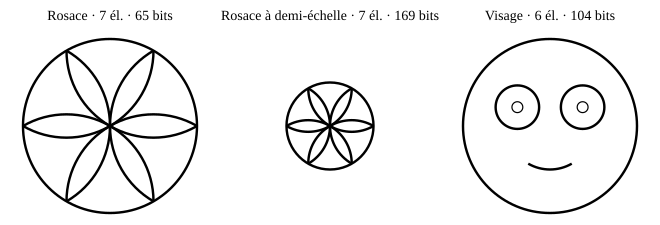

ROSACE          65 bits : (1,0,0,0,0,0) (3,1,0,1,1,0) (2,1,1,1,0,0) (7,1,1,1,0,0) (6,1,1,1,0,0) (5,1,0,1,1,0) (4,1,0,1,1,0)


ROSACE_DEMI    169 bits : (14,0,0,0,0,0) (16,14,0,14,1,0) (15,14,1,14,0,0) (20,14,1,14,0,0) (19,14,1,14,0,0) (18,14,0,14,1,0) (17,14,0,14,1,0)


VISAGE         104 bits : (1,0,0,0,0,0) (57,0,0,0,0,0) (53,0,0,0,0,0) (593,0,0,0,0,1) (589,0,0,0,0,1) (14,29,0,30,0,0)


In [9]:
int NumDe(Point centre, double rayon) =>
    catalogue.First(c => Math.Abs(c.Rayon - rayon) < Epsilon && Distance(c.Centre, centre) < 1e-6).Numero;
ArcLegal ArcPar(int c, int s, int e, double via)
{
    var pc = ParNumero(c).Centre;
    for (int ks = 0; ks < 2; ks++)
        for (int ke = 0; ke < 2; ke++)
        {
            var (debut, fin) = (PointExtremite(c, s, ks), PointExtremite(c, e, ke));
            double aS = Modulo(Angle(pc, debut), 360), aE = Modulo(Angle(pc, fin), 360);
            // Le test choisit un arc horaire passant par la direction fournie.
            if (Math.Abs(aS - aE) >= 1e-6 && Modulo(via - aE, 360) < Modulo(aS - aE, 360))
                return new ArcLegal(c, s, ks, e, ke, 0);
        }
    throw new ArgumentException($"Aucun arc de {c} entre {s} et {e} ne passe par {via}.");
}
ArcLegal Cercle(int c, int m = 0) => new(c, 0, 0, 0, 0, m);
ArcLegal[] Rosace(double rayon, int limite)
{
    var arcs = new List<ArcLegal> { Cercle(limite) };
    for (int a = 0; a < 360; a += 60)
    {
        double rad = a * Math.PI / 180;
        var centre = new Point(rayon * Math.Cos(rad), rayon * Math.Sin(rad));
        int c = NumDe(centre, rayon);
        var p = ParNumero(c).Centre;
        arcs.Add(ArcPar(c, limite, limite, Modulo(Angle(p, new Point(0, 0)), 360)));
    }
    return arcs.ToArray();
}
var cadre = Cercle(1);
var rosace = Rosace(1, 1);
var rosaceDemi = Rosace(0.5, NumDe(new Point(0, 0), 0.5));
double s3 = Math.Sqrt(3) / 2;
var oeilG = new Point(-0.375, 0.25 * s3);
var oeilD = new Point(0.375, 0.25 * s3);
var visage = new[] { cadre, Cercle(NumDe(oeilG, 0.25)), Cercle(NumDe(oeilD, 0.25)),
    Cercle(NumDe(oeilG, 0.0625), 1), Cercle(NumDe(oeilD, 0.0625), 1),
    ArcPar(NumDe(new Point(0, 0), 0.5), NumDe(new Point(0.5, -s3), 0.5),
           NumDe(new Point(-0.5, -s3), 0.5), 270) };
void Montage(IEnumerable<(string Nom, ArcLegal[] Arcs)> dessins)
{
    const int panneau = 220;
    int i = 0;
    var contenu = new StringBuilder();
    foreach (var (nom, arcs) in dessins)
    {
        int x = i * panneau + panneau / 2;
        contenu.Append(Svg($"<text x='{x}' y='20' font-size='14' text-anchor='middle'>{nom} · {arcs.Length} él. · {Cout(arcs)} bits</text>"));
        contenu.Append(Dessiner(arcs, x, 126, 87, 0.028));
        i++;
    }
    display(new FigureSvg(SvgComplet(panneau * i, 225, contenu.ToString())));
}
Montage(new[] { ("Rosace", rosace), ("Rosace à demi-échelle", rosaceDemi), ("Visage", visage) });
foreach (var (nom, forme) in new[] { ("ROSACE", rosace), ("ROSACE_DEMI", rosaceDemi), ("VISAGE", visage) })
{
    string codes = string.Join(" ", forme.Select(a => $"({a.C},{a.S},{a.Ks},{a.E},{a.Ke},{a.M})"));
    Console.WriteLine($"{nom,-13} {Cout(forme),4} bits : {codes}");
}

### Lecture : cout en bits des trois dessins

- La **rosace** coûte **65 bits** pour sept éléments : tous ses arcs commencent
  et finissent sur le cadre, le cercle numéro 1, qui est le moins cher.
- La **même rosace à l'échelle 1/2** coûte **169 bits**, soit 2,6 fois plus,
  pour une forme identique : ses cercles portent les numéros 14 à 20 au lieu
  de 1 à 7.
- Dans le **visage** (104 bits), les deux pupilles (numéros 589 et 593, rayon
  1/16) coûtent 23 bits chacune. Ces deux petits points font **44 %** du coût
  du dessin, et les deux yeux qui les entourent n'en font que 13 bits chacun.

Le schéma récompense donc les grands traits, et il pénalise le détail fin plus
que la forme d'ensemble.

### Exercice 2 — Un dessin moins coûteux que le visage

Composer, mesurer et rendre une silhouette reconnaissable. Comparer son coût aux 104 bits du visage. Tester de gros cercles et le numéro 1 comme point d’intersection.

In [10]:
// TODO : composer une silhouette reconnaissable avec un nombre limité d'arcs.
// Étape 1 : privilégier les cercles à petit numéro et composer un motif.
// Étape 2 : afficher le résultat et comparer son coût en bits à celui du visage.
Func<ArcLegal[]> DessinEconomique = () => null; // TODO : composer des arcs.
Console.WriteLine(DessinEconomique() is null
    ? "Exercice à compléter : le dessin moins coûteux que le visage."
    : "Affichez votre dessin avant de comparer son coût.");

Exercice à compléter : le dessin moins coûteux que le visage.


Le papier note (§4.3) que l'artiste exploitera souvent des symétries propres au
dessin pour compresser encore la description. La rosace est invariante par
rotation de 60°, et cette rotation envoie chaque niveau du réseau sur lui-même :
un pétale tourné reste un arc légal. On le mesure.

In [11]:
int CoutSymetrique(IEnumerable<ArcLegal> fixes, IEnumerable<ArcLegal> motif, int k) =>
    Cout(fixes) + Cout(motif) + 2 + GammaBits(k);
// L'opcode répète un pétale par rotation, et le cadre ne se répète pas.
int prixSymetrique = CoutSymetrique(new[] { cadre }, new[] { rosace[1] }, 6);
Console.WriteLine($"Rosace, six pétales écrits      : {Cout(rosace)} bits.");
Console.WriteLine($"Rosace, un pétale + répétition  : {prixSymetrique} bits.");
if ((Cout(rosace), prixSymetrique) != (65, 19))
    throw new InvalidOperationException("Le contrôle de symétrie de la rosace a échoué.");

Rosace, six pétales écrits      : 65 bits.


Rosace, un pétale + répétition  : 19 bits.


### Lecture : compression par symetrie (gain x3,4)

Écrire un seul pétale et l'instruction « répète six fois » fait passer la
rosace de **65 à 19 bits**, soit un gain d'un facteur 3,4. C'est la compression
par symétrie propre au dessin que le §4.3 annonce. Elle ne coûte rien en
légalité : une rotation de 60° envoie chaque niveau du réseau sur lui-même.

### Exercice 3 — Le motif en miroir

Tester d’abord la fermeture du catalogue par réflexion gauche-droite, puis chiffrer le prix d’un motif codé une fois avec un opcode supplémentaire.

In [12]:
// TODO : vérifier le miroir du catalogue et calculer le prix d'un opcode de deux bits.
// Étape 1 : retrouver les centres réfléchis à rayon égal avant de coder.
// Étape 2 : identifier les éléments écrits et leur duplication, puis mesurer le gain.
Point? Miroir(Point p) => null; // TODO : réfléchir le centre et vérifier l'appartenance au même niveau.
Console.WriteLine(Miroir(oeilG) is null
    ? "Exercice à compléter : réflexion gauche-droite et gain en bits."
    : "Mesurez le prix du motif et son gain par rapport au visage complet.");

Exercice à compléter : réflexion gauche-droite et gain en bits.


Le §4.3 donne aussi le contre-exemple : « avec beaucoup de très petits cercles,
on peut tout dessiner », mais cela demande beaucoup d'information. On retrace la
rosace avec les cercles de rayon 1/16 les plus proches de son tracé. Un témoin
s'y ajoute : six arcs tirés **au hasard** (graine fixe) parmi les treize mêmes
premiers cercles, de sorte qu'ils restent dans le cadre.

In [13]:
IEnumerable<Point> Echantillonner(IEnumerable<ArcLegal> arcs, int nombre = 400)
{
    foreach (var a in arcs)
    {
        var c = ParNumero(a.C);
        double debut = 0, pas = 2 * Math.PI / nombre;
        if (a.S != 0)
        {
            debut = Angle(c.Centre, PointExtremite(a.C, a.S, a.Ks)) * Math.PI / 180;
            double fin = Angle(c.Centre, PointExtremite(a.C, a.E, a.Ke)) * Math.PI / 180;
            pas = -Modulo(debut - fin, 2 * Math.PI) / (nombre - 1);
        }
        for (int i = 0; i < nombre; i++)
        {
            double t = debut + i * pas;
            yield return new Point(c.Centre.X + c.Rayon * Math.Cos(t), c.Centre.Y + c.Rayon * Math.Sin(t));
        }
    }
}
ArcLegal[] EnPetitsCercles(IEnumerable<ArcLegal> arcs, double r)
{
    var centres = catalogue.Where(c => Math.Abs(c.Rayon - r) < Epsilon).ToArray();
    // Chaque échantillon prend le centre admissible le plus proche. Le catalogue fixe les ex æquo.
    var choisis = new SortedSet<int>();
    foreach (var p in Echantillonner(arcs))
    {
        var meilleur = centres.MinBy(c => Carre(c.Centre.X - p.X) + Carre(c.Centre.Y - p.Y));
        choisis.Add(meilleur.Numero);
    }
    return choisis.Select(n => Cercle(n, 3)).ToArray();
}
var rosaceGrains = EnPetitsCercles(rosace, 0.0625);
Console.WriteLine($"Rosace en cercles de rayon 1/16 : {rosaceGrains.Length} cercles, {Cout(rosaceGrains)} bits, numéros {rosaceGrains[0].C} à {rosaceGrains[^1].C}.");

Rosace en cercles de rayon 1/16 : 357 cercles, 9179 bits, numéros 425 à 1427.


**Ce que le contrôle isole**

La cellule précédente a fait varier le **matériau** : la même rosace, retracée en cercles de rayon 1/16. Le contrôle fait l'opération duale — il **fixe** le matériau et ne laisse varier que l'**arrangement** : six arcs tirés au hasard (graine 1997) parmi les mêmes treize premiers cercles que ceux de la rosace, avec le même budget de sept éléments, et pour seules contraintes d'être traçables (extrémités éloignées de plus de 0,3, tracé contenu dans le disque). Si le compteur de bits ne mesurait que le matériau, ce tirage et la rosace tomberaient au même prix. La figure affiche les cinq dessins sous un même titre — nombre d'éléments, coût en bits — pour que l'œil et le compteur jugent ensemble, et la lecture qui suit chiffre l'écart.
 La graine 1997 rend le tirage rejouable : le témoin n'est pas une moyenne mais un exemplaire figé, consultable à l'identique à chaque exécution.


`Random(1997)` rend le tirage C# reproductible. Le flux Python emploie un autre générateur et sélectionne d’autres arcs à la même graine nominale.

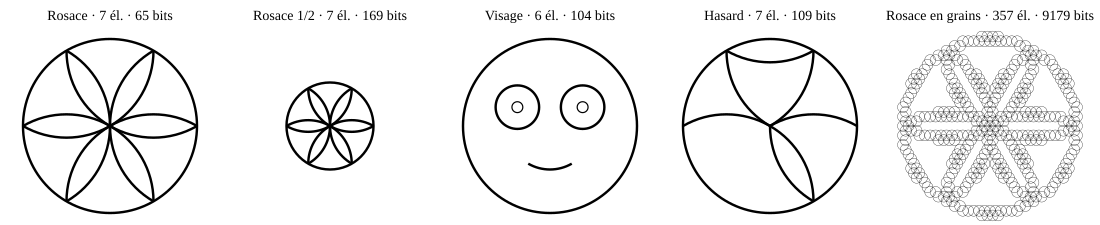

Rosace               7 éléments     65 bits.


Rosace 1/2           7 éléments    169 bits.


Visage               6 éléments    104 bits.


Hasard               7 éléments    109 bits.


Rosace en grains   357 éléments   9179 bits.


In [14]:
var rng = new Random(1997);
ArcLegal ArcAleatoire()
{
    while (true)
    {
        // Le témoin sélectionne le même ensemble de petits indices que la rosace, avec rejet géométrique.
        int c = rng.Next(2, 14), s = rng.Next(1, 14), e = rng.Next(1, 14);
        int ks = rng.Next(2), ke = rng.Next(2);
        var p = Extremites(c, s);
        var q = Extremites(c, e);
        if (p.Length == 0 || q.Length == 0) continue;
        var a = new ArcLegal(c, s, ks, e, ke, 0);
        if (Distance(p[Math.Min(ks, p.Length - 1)], q[Math.Min(ke, q.Length - 1)]) > 0.3 &&
            Echantillonner(new[] { a }, 60).All(p => Norme(p) <= 1 + 1e-6))
            return a;
    }
}
var hasard = new[] { cadre }.Concat(Enumerable.Range(0, 6).Select(_ => ArcAleatoire())).ToArray();
var dessins = new[] { ("Rosace", rosace), ("Rosace 1/2", rosaceDemi), ("Visage", visage),
    ("Hasard", hasard), ("Rosace en grains", rosaceGrains) };
Montage(dessins);
foreach (var (nom, arcs) in dessins)
    Console.WriteLine($"{nom,-18} {arcs.Length,3} éléments  {Cout(arcs),5} bits.");

### Lecture : l’arrangement change le coût

L’approximation en très petits cercles conserve une forme lisible et oblige le code
à employer de nombreux grands numéros. La ligne « rosace en grains » donne ce coût.
Le témoin aléatoire conserve les sept éléments du dessin de référence et peut coûter
plus cher en choisissant d’autres intersections. Le tableau distingue le prix de la
description et la préférence visuelle, qui dépend aussi du lecteur.

## 5. Deux observateurs : le schéma des cercles contre les pixels

Au §6.1, la beauté est **relative à l'observateur** : elle dépend de
l'algorithme de codage *C* qu'il porte. On instancie deux observateurs.

- Le premier connaît le **schéma des cercles** : il paie les bits du code des
  arcs.
- Le second ne connaît que des **pixels** : il paie l'image rendue en 256×256
  sur 1 bit, compressée par LZMA (et, pour référence, par PNG).

In [15]:
const int Taille = 256;
async Task<byte[]> Bitmap(ArcLegal[] arcs)
{
    double centre = Taille / 2.0, echelle = Taille / 2.1;
    // Une fenêtre de 2,1 unités, un trait d'un point et le même seuil 128 que le Python.
    string svg = SvgComplet(Taille, Taille, Dessiner(arcs, centre, centre, echelle, 2.1 / 72));
    byte[] png = await AppelerOutil("rsvg-convert", Encoding.UTF8.GetBytes(svg), "--format=png");
    byte[] gris = await AppelerOutil("magick", png, "png:-", "-depth", "8", "gray:-");
    if (gris.Length != Taille * Taille)
        throw new InvalidOperationException("Le rasteriseur n'a pas émis un canal 256 × 256.");
    return gris.Select(p => p < 128 ? (byte)1 : (byte)0).ToArray();
}
byte[] EmpaqueterBits(byte[] pixels)
{
    var flux = new byte[(pixels.Length + 7) / 8];
    // L'ordre fort vers faible est le même que numpy.packbits sans paramètre bitorder.
    for (int i = 0; i < pixels.Length; i++)
        flux[i / 8] |= (byte)(pixels[i] << (7 - i % 8));
    return flux;
}
Task<byte[]> BitmapPng(byte[] pixels)
{
    var enTete = Encoding.ASCII.GetBytes($"P5\n{Taille} {Taille}\n255\n");
    var pgm = enTete.Concat(pixels.Select(p => p == 1 ? (byte)0 : (byte)255)).ToArray();
    return AppelerOutil("magick", pgm, "pgm:-", "png:-");
}
var lignes = new List<(string Nom, int Description, int Xz, int Png, int Brut)>();
Console.WriteLine($"{"Dessin",-18} {"cercles",8} {"XZ 1 bit",10} {"PNG",8} {"brut",8} {"XZ/cercles",10}");
foreach (var (nom, dessin) in dessins)
{
    var pixels = await Bitmap(dessin);
    var flux = EmpaqueterBits(pixels);
    int xz = 8 * (await Compresser(flux, "-9")).Length;
    int png = 8 * (await BitmapPng(pixels)).Length;
    int description = Cout(dessin);
    lignes.Add((nom, description, xz, png, pixels.Length));
    Console.WriteLine($"{nom,-18} {description,8} {xz,10} {png,8} {pixels.Length,8} {(double)xz / description,10:F1}");
}

Dessin              cercles   XZ 1 bit      PNG     brut XZ/cercles


Rosace                   65      10144    13824    65536      156.1


Rosace 1/2              169       5760     7608    65536       34.1


Visage                  104       8512    11960    65536       81.8


Hasard                  109      10976    14424    65536      100.7


Rosace en grains       9179      12064    15624    65536        1.3


### Lecture : inversion des classements

Comparez la rosace au demi-format selon le schéma puis selon le flux XZ de pixels monochromes.
Le schéma utilise des numéros plus longs pour les cercles plus petits. Le rasteriseur peut
au contraire laisser davantage d’espace uniforme autour de la petite rosace, dont le flux se
compresse mieux. La version en grains fait payer beaucoup plus de symboles, même si ses
pixels conservent une partie de la structure de la rosace.

Le tableau rapporte des bits de description Elias, des bits XZ sur le bitmap compacté,
des bits de PNG et 65 536 bits bruts. L’encadrement, le trait, l’anticrénelage et le coût
fixe du conteneur sont des paramètres de l’observateur pixel.

## 6. Le style comme schéma partagé

Le §6.2 définit la qualité d'un style *C* par l'équation (3) : *C* est bon s'il
minimise la somme de deux termes. Le premier est l'information nécessaire pour
calculer les dessins *S* à partir de *C*. Le second est l'information nécessaire
pour calculer *C* à partir de ce que sait déjà l'observateur. Le §5 en tire une
conséquence : coder plusieurs dessins **ensemble** coûte moins cher que les
coder séparément, parce que le schéma est payé une seule fois. On mesure L(*C*)
par la taille compressée du code source des fonctions du schéma.

In [16]:
var nomsSchema = new[] { nameof(Intersections), nameof(Regle1Cloture), nameof(Reseau), nameof(Catalogue),
    nameof(GammaBits), nameof(BitsArc), nameof(PointExtremite), nameof(Angle), nameof(Dessiner) };
byte[] sourceSchema = LireDeclarations(Carnet, nomsSchema);
int lC = 8 * (await Compresser(sourceSchema, "-9")).Length;
// On égalise le groupe de dessins avant de changer le nombre de facturations du schéma.
int prixDessins = Cout(rosace) + Cout(visage) + Cout(rosaceDemi);
int separes = 3 * lC + prixDessins;
int ensemble = lC + prixDessins;
Console.WriteLine($"Schéma : {sourceSchema.Length} octets UTF-8, L(C) = {lC} bits (XZ).");
Console.WriteLine($"Trois dessins seuls : {prixDessins} bits. Séparés : {separes} bits. Ensemble : {ensemble} bits.");
Console.WriteLine($"Économie partagée : {separes - ensemble} bits = 2 × L(C).");
if (lignes[0].Xz > lignes[0].Description)
{
    int seuil = lC / (lignes[0].Xz - lignes[0].Description) + 1;
    Console.WriteLine($"Première mutualisation rentable à coût unitaire de la rosace : {seuil} dessin(s).");
}
else
{
    Console.WriteLine("À ce coût unitaire, le schéma ne s’amortit pas face aux pixels XZ.");
}

Schéma : 4415 octets UTF-8, L(C) = 15360 bits (XZ).


Trois dessins seuls : 338 bits. Séparés : 46418 bits. Ensemble : 15698 bits.


Économie partagée : 30720 bits = 2 × L(C).


Première mutualisation rentable à coût unitaire de la rosace : 2 dessin(s).


### Lecture : le schéma se paie une fois

La mesure comprime les neuf déclarations C# du schéma. La cellule rapporte
le coût du schéma, des trois dessins seuls, des descriptions individuelles et de
leur description commune. L’écart vaut deux fois le coût du schéma, car sa
déclaration est facturée une seule fois au lieu de trois.

Le seuil calculé pour une suite de rosaces de référence donne le premier
nombre de dessins auquel le coût mutualisé devient inférieur au coût des
bitmaps compressés séparément. Il dépend du texte C#, du compresseur et du rendu.
C’est un exemple mesuré de l’argument du §6.2, pas une mesure de la difficulté
d’apprentissage d’un style par une personne.

## 7. Retour sur les exercices

Comparer les contacts calculés, le coût d’un dessin choisi et le gain d’un motif réfléchi aux trois expériences précédentes.

## 8. Conclusion

Ce jalon a reconstruit le schéma des cercles fractals de Schmidhuber et l'a
mesuré.

- **Ce qui tient.** Les comptes du papier (12 et 31) se reproduisent depuis les
  règles seules, et les règles engendrent un réseau triangulaire à chaque
  échelle. Le codage par numéros récompense bien les grands traits : une rosace
  coûte 65 bits, sa version en grains 9179, et une symétrie la ramène à 19.
- **Ce que la mesure précise.**
  - Le facteur « environ quatre » entre niveaux est une limite, voisine de 2,6
    pour les gros cercles.
  - Une description courte ne distingue pas un dessin juste d'un dessin quelconque : le visage
    coûte 104 bits, et le témoin aléatoire dépend des arcs tirés.
  - Le style n'est « bon marché » que pour qui l'a déjà appris : la section 6 donne le coût mesuré du schéma et son amortissement.
- **Ce qui ressort le plus nettement.** Changer d'observateur, en passant des
  cercles aux pixels, inverse le classement de deux rosaces de même forme.
  C'est la relativité à l'observateur du §6.1, rendue mesurable.

Le fil de la longueur de description continue dans le rayon : la CLIP-guided
diffusion (05-1) et CLIPasso (05-2) remplaceront le schéma écrit à la main par
une mesure apprise, et c'est un observateur appris qui jugera du « juste ».

**Rattachements** : Epic #16774 (jalon 3) · Epic #16775 (curation Schmidhuber,
source D1) · jalons précédents : [05-0](05-0-Generateurs-Symboliques.ipynb) et [05-0b](05-0b-Demoscene-Intros-Procedurales-Python.ipynb).